In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

import shap
import warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

In [2]:
#Source:  Kaggle/UCL,Portuguese Schools)
#Link: https://www.kaggle.com/datasets/larsen0966/student-performance-data-set
df = pd.read_csv('StudentData.csv')
print("Shape of dataset:", df.shape)
df.head()

Shape of dataset: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [3]:
data_dictionary = {
    "school": "Student's school -> Binary: 'GP' - Gabriel Pereira or 'MS' - Mousinho da Silveira",
    "sex": "Student's sex -> Binary: 'F' - female or 'M' - male",
    "age": "Student's age -> Numeric: from 15 to 22",
    "address": "Home address type -> Binary: 'U' - urban or 'R' - rural",
    "famsize": "Family size -> Binary: 'LE3' - less or equal to 3 or 'GT3' - greater than 3",
    "Pstatus": "Parent's cohabitation status -> Binary: 'T' - living together or 'A' - apart",
    "Medu": "Mother's education -> Numeric: 0-none, 1-primary(4th), 2-5th-9th, 3-secondary, 4-higher",
    "Fedu": "Father's education -> Numeric: 0-none, 1-primary(4th), 2-5th-9th, 3-secondary, 4-higher",
    "Mjob": "Mother's job -> Nominal: 'teacher','health','services','at_home','other'",
    "Fjob": "Father's job -> Nominal: 'teacher','health','services','at_home','other'",
    "reason": "Reason to choose this school -> Nominal: 'home','reputation','course','other'",
    "guardian": "Student's guardian -> Nominal: 'mother','father','other'",
    "traveltime": "Home to school travel time -> Numeric: 1(<15min), 2(15-30min), 3(30min-1hr), 4(>1hr)",
    "studytime": "Weekly study time -> Numeric: 1(<2hrs), 2(2-5hrs), 3(5-10hrs), 4(>10hrs)",
    "failures": "Number of past class failures -> Numeric: n if 1<=n<3, else 4",
    "schoolsup": "Extra educational school support -> Binary: 'yes' or 'no'",
    "famsup": "Family educational support -> Binary: 'yes' or 'no'",
    "paid": "Extra paid classes (within course subject) -> Binary: 'yes' or 'no'",
    "activities": "Extra-curricular activities -> Binary: 'yes' or 'no'",
    "nursery": "Attended nursery school -> Binary: 'yes' or 'no'",
    "higher": "Wants to take higher education -> Binary: 'yes' or 'no'",
    "internet": "Internet access at home -> Binary: 'yes' or 'no'",
    "romantic": "In a romantic relationship -> Binary: 'yes' or 'no'",
    "famrel": "Quality of family relationships -> Numeric: 1(very bad) to 5(excellent)",
    "freetime": "Free time after school -> Numeric: 1(very low) to 5(very high)",
    "goout": "Going out with friends -> Numeric: 1(very low) to 5(very high)",
    "Dalc": "Workday alcohol consumption -> Numeric: 1(very low) to 5(very high)",
    "Walc": "Weekend alcohol consumption -> Numeric: 1(very low) to 5(very high)",
    "health": "Current health status -> Numeric: 1(very bad) to 5(very good)",
    "absences": "Number of school absences -> Numeric: 0 to 93",
    "G1": "First period grade -> Numeric: 0 to 20",
    "G2": "Second period grade -> Numeric: 0 to 20",
    "G3": "Final grade (target source) -> Numeric: 0 to 20"
}

print(f"{'Attribute':<12} | Description")
print("-"*90)
for attr, desc in data_dictionary.items():
    print(f"{attr:<12} | {desc}")

Attribute    | Description
------------------------------------------------------------------------------------------
school       | Student's school -> Binary: 'GP' - Gabriel Pereira or 'MS' - Mousinho da Silveira
sex          | Student's sex -> Binary: 'F' - female or 'M' - male
age          | Student's age -> Numeric: from 15 to 22
address      | Home address type -> Binary: 'U' - urban or 'R' - rural
famsize      | Family size -> Binary: 'LE3' - less or equal to 3 or 'GT3' - greater than 3
Pstatus      | Parent's cohabitation status -> Binary: 'T' - living together or 'A' - apart
Medu         | Mother's education -> Numeric: 0-none, 1-primary(4th), 2-5th-9th, 3-secondary, 4-higher
Fedu         | Father's education -> Numeric: 0-none, 1-primary(4th), 2-5th-9th, 3-secondary, 4-higher
Mjob         | Mother's job -> Nominal: 'teacher','health','services','at_home','other'
Fjob         | Father's job -> Nominal: 'teacher','health','services','at_home','other'
reason       | Reason to ch

In [8]:
df.info()
print("\nMissing values per column:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  
 21  inte

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


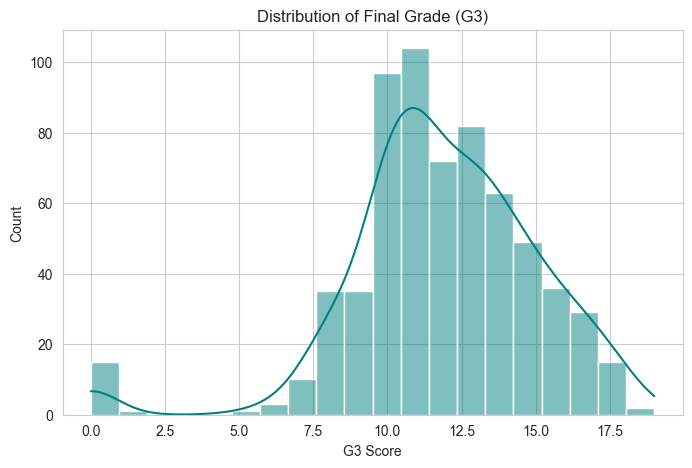

In [9]:
plt.figure(figsize=(8,5))
sns.histplot(df['G3'], bins=20, kde=True, color='teal')
plt.title('Distribution of Final Grade (G3)')
plt.xlabel('G3 Score')
plt.show()

Performance
Medium    418
High      131
Low       100
Name: count, dtype: int64


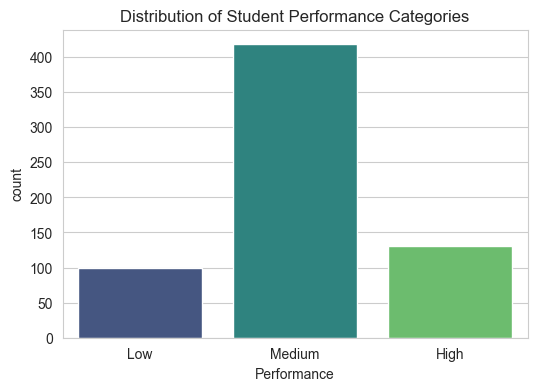

In [ ]:
def categorize_performance(grade):
    if grade < 10:
        return 'Low'
    elif grade < 15:
        return 'Medium'
    else:
        return 'High'
df['Performance'] = df['G3'].apply(categorize_performance)
print(df['Performance'].value_counts())
plt.figure(figsize=(6,4))
sns.countplot(x='Performance', data=df, order=['Low','Medium','High'], palette='viridis')
plt.title('Distribution of Student Performance Categories')
plt.show()

In [ ]:
categorical_cols = df.select_dtypes(include='object').columns.tolist()
categorical_cols.remove('Performance')
print("Categorical columns to encode:", categorical_cols)
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le
df.head()

Categorical columns to encode: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,Performance
0,0,0,18,1,0,0,4,4,0,4,...,3,4,1,1,3,4,0,11,11,Medium
1,0,0,17,1,0,1,1,1,0,2,...,3,3,1,1,3,2,9,11,11,Medium
2,0,0,15,1,1,1,1,1,0,2,...,3,2,2,3,3,6,12,13,12,Medium
3,0,0,15,1,0,1,4,2,1,3,...,2,2,1,1,5,0,14,14,14,Medium
4,0,0,16,1,0,1,3,3,2,2,...,3,2,1,2,5,0,11,13,13,Medium


In [ ]:
X = df.drop(columns=['G3', 'Performance'])
y = df['Performance']
print("Feature set shape:", X.shape)
print("Target classes:", y.unique())

Feature set shape: (649, 32)
Target classes: <StringArray>
['Medium', 'High', 'Low']
Length: 3, dtype: str


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 519
Testing samples: 130


In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    random_state=42
)
rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [19]:
param_grid = {
    'n_estimators': [200, 300, 400],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}
grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)
print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)
print("Accuracy in %:",grid_search.best_score_*100,"%")
rf_model = grid_search.best_estimator_

Best Parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Best CV Accuracy: 0.8959484690067214
Accuracy in %: 89.59484690067214 %


In [21]:
y_pred = rf_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {accuracy*100:.2f}%")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Test Accuracy: 88.46%

Classification Report:

              precision    recall  f1-score   support

        High       0.91      0.77      0.83        26
         Low       0.93      0.70      0.80        20
      Medium       0.87      0.96      0.92        84

    accuracy                           0.88       130
   macro avg       0.90      0.81      0.85       130
weighted avg       0.89      0.88      0.88       130



In [23]:
cv_scores = cross_val_score(rf_model, X, y, cv=5, scoring='accuracy')
print("Cross-Validation Accuracy Scores:", cv_scores)
print(f"Mean CV Accuracy: {cv_scores.mean()*100:.2f}% (+/- {cv_scores.std()*100:.2f}%)")

Cross-Validation Accuracy Scores: [0.83846154 0.88461538 0.88461538 0.89230769 0.86821705]
Mean CV Accuracy: 87.36% (+/- 1.93%)


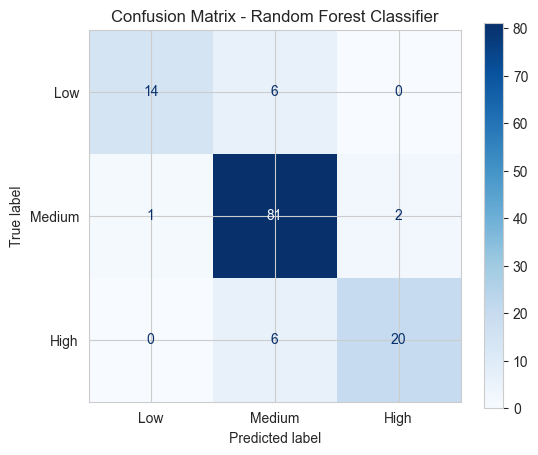

In [25]:
cm = confusion_matrix(y_test, y_pred, labels=['Low','Medium','High'])
fig, ax = plt.subplots(figsize=(6,5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Low','Medium','High'])
disp.plot(cmap='Blues', ax=ax, colorbar=True)
plt.title('Confusion Matrix - Random Forest Classifier')
plt.show()

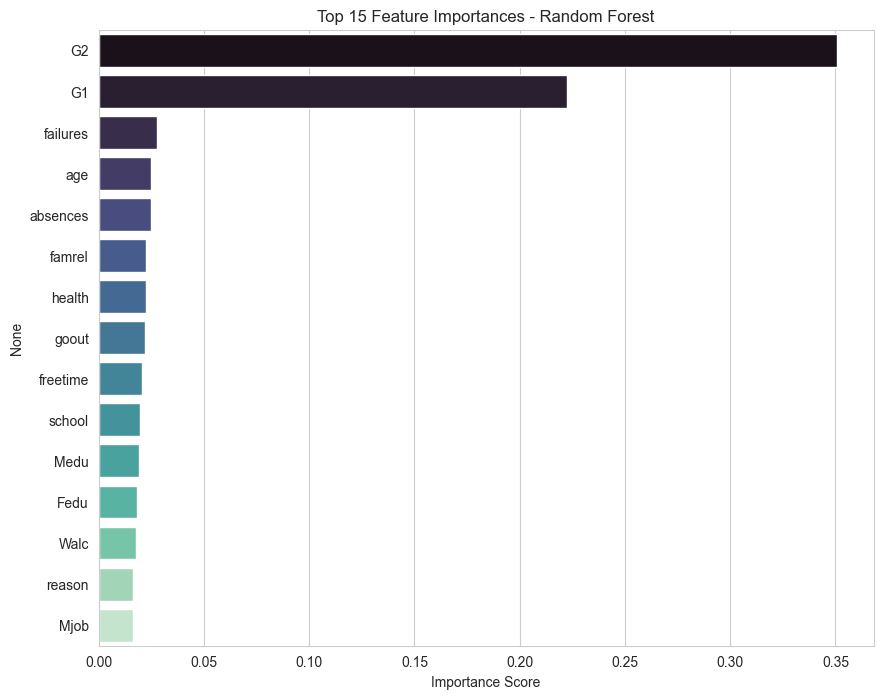

In [27]:
importances = pd.Series(rf_model.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False)
plt.figure(figsize=(10,8))
sns.barplot(x=importances.values[:15], y=importances.index[:15], palette='mako')
plt.title('Top 15 Feature Importances - Random Forest')
plt.xlabel('Importance Score')
plt.show()

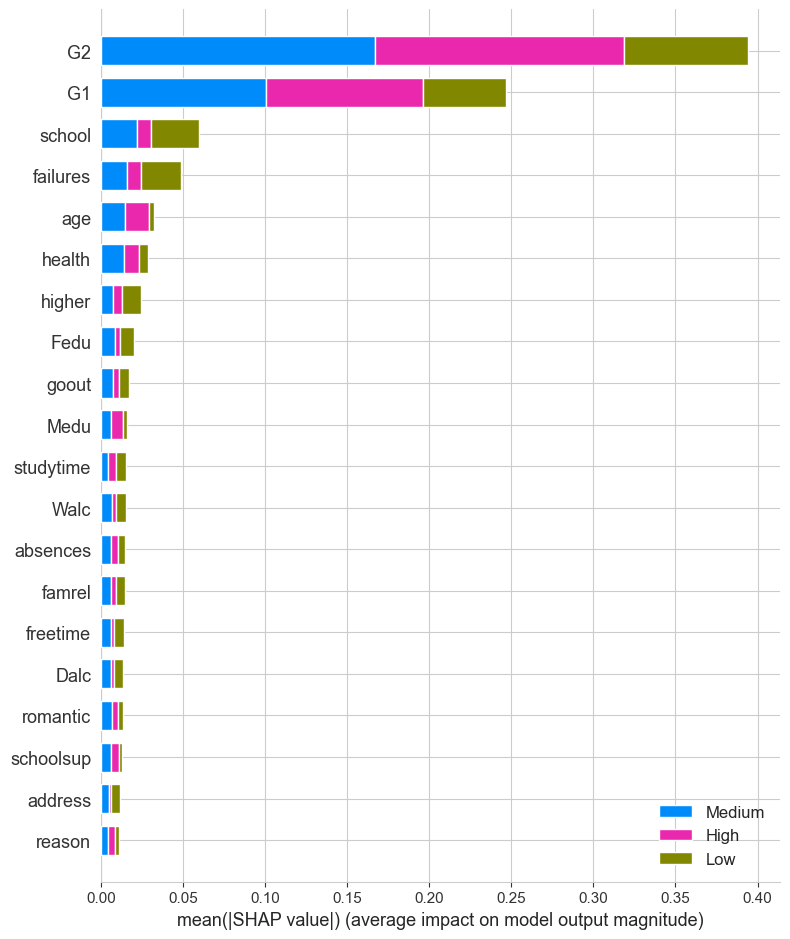

In [29]:
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test)
shap.summary_plot(shap_values, X_test, plot_type='bar', class_names=rf_model.classes_)

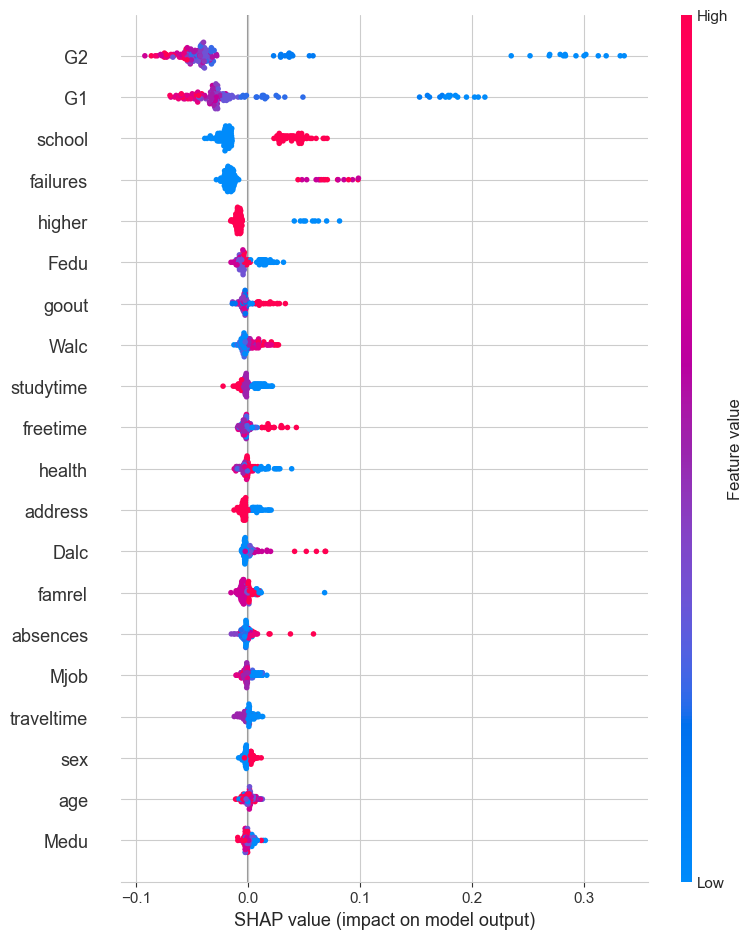

In [30]:
class_index = list(rf_model.classes_).index('Low')
shap.summary_plot(shap_values[:, :, class_index], X_test)

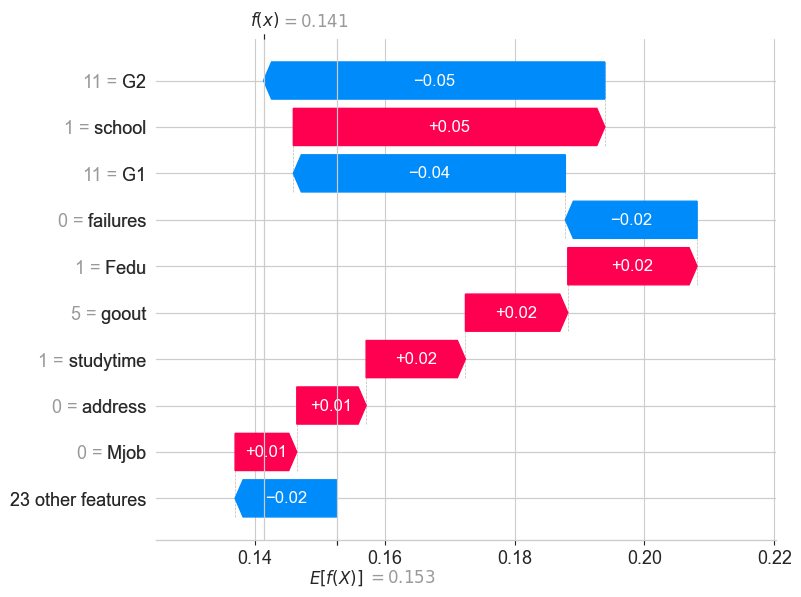

In [31]:
sample_idx = 0
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[sample_idx, :, class_index],
        base_values=explainer.expected_value[class_index],
        data=X_test.iloc[sample_idx],
        feature_names=X_test.columns.tolist()
    )
)

In [32]:
print("="*60)
print("STUDENT PERFORMANCE PREDICTOR - MODEL SUMMARY REPORT")
print("="*60)
print(f"Dataset size: {df.shape[0]} records, {df.shape[1]} features")
print(f"Model: Random Forest Classifier")
print(f"Test Accuracy: {accuracy*100:.2f}%")
print(f"Mean CV Accuracy: {cv_scores.mean()*100:.2f}%")
print("\nTop 5 Most Influential Features:")
print(importances.head(5))
print("\nKey Insight: SHAP analysis confirms prior academic performance (G1, G2),")
print("absences, and study time are the strongest predictors of final outcomes,")
print("consistent with feature importance rankings from Random Forest.")
print("="*60)

STUDENT PERFORMANCE PREDICTOR - MODEL SUMMARY REPORT
Dataset size: 649 records, 34 features
Model: Random Forest Classifier
Test Accuracy: 88.46%
Mean CV Accuracy: 87.36%

Top 5 Most Influential Features:
G2          0.350625
G1          0.222682
failures    0.027817
age         0.024817
absences    0.024675
dtype: float64

Key Insight: SHAP analysis confirms prior academic performance (G1, G2),
absences, and study time are the strongest predictors of final outcomes,
consistent with feature importance rankings from Random Forest.


In [5]:
r1  = df['G1'].corr(df['G3'])
r2  = df['G2'].corr(df['G3'])
r12 = df['G1'].corr(df['G2'])

beta1 = (r1 - r2 * r12) / (1 - r12**2)
beta2 = (r2 - r1 * r12) / (1 - r12**2)

b1 = beta1 * df['G3'].std() / df['G1'].std()
b2 = beta2 * df['G3'].std() / df['G2'].std()
intercept = df['G3'].mean() - b1 * df['G1'].mean() - b2 * df['G2'].mean()

g1 = float(input("Enter G1 (0-20): "))
g2 = float(input("Enter G2 (0-20): "))

g3 = np.clip(intercept + b1 * g1 + b2 * g2, 0, 20)
print(f"Predicted final score (G3): {g3:.1f} / 20")

Predicted final score (G3): 18.1 / 20
